## Attrition Prediction

In [1]:
import time, pickle, subprocess, sys, warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import cloudpickle                      
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

Load Data

In [2]:
df = pd.read_excel("Employee-Attrition.xlsx")       

In [3]:
print(df.shape)         
print(df.dtypes)        
print(df.isnull().sum().sum())

(1470, 35)
Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EmployeeCount               int64
EmployeeNumber              int64
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
Over18                        str
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StandardHours               int64
StockOptionLevel            int64
TotalWorkingYears           int64
Tra

In [4]:
print(df['Attrition'].value_counts())
print(df.groupby('OverTime')['Attrition'].apply(lambda x: (x == 'Yes').mean()))

Attrition
No     1233
Yes     237
Name: count, dtype: int64
OverTime
No     0.104364
Yes    0.305288
Name: Attrition, dtype: float64


Data Visualization

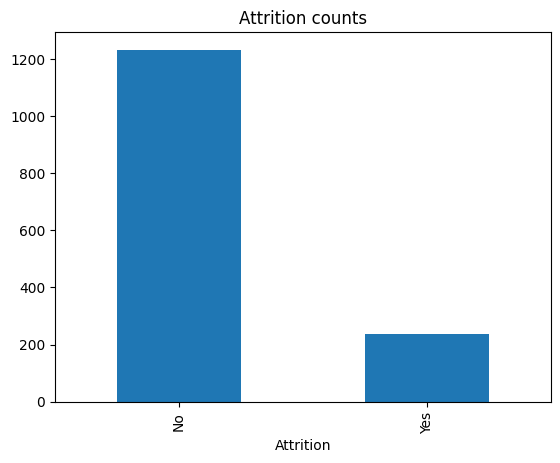

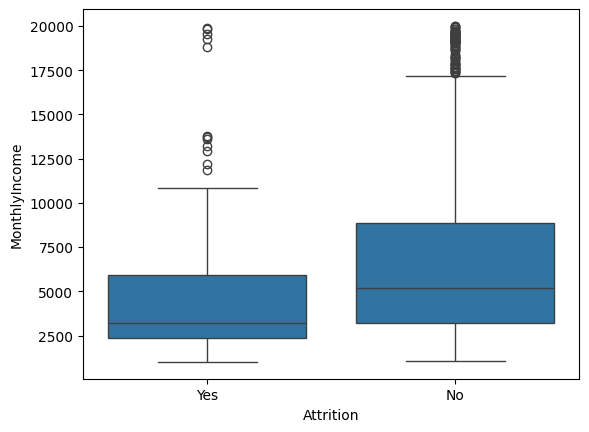

In [6]:
df['Attrition'].value_counts().plot(kind='bar', title='Attrition counts')
plt.show()

sns.boxplot(data=df, x='Attrition', y='MonthlyIncome')
plt.show()

Data Cleaning

In [7]:
df = df.drop(columns=['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber'])

df['Attrition'] = df['Attrition'].map({'No': 0, 'Yes': 1})
df['PerformanceRating'] = df['PerformanceRating'].map({3: 0, 4: 1})

In [8]:
df['Age'].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

Feature engineering

In [9]:
SATISFACTION_COLS = ['JobSatisfaction', 'EnvironmentSatisfaction',
                     'RelationshipSatisfaction', 'WorkLifeBalance']
BOUND_COLS = ['PercentSalaryHike', 'TrainingTimesLastYear', 'JobInvolvement', 'StockOptionLevel']

def add_features(data, bounds):
    data = data.copy()
    data['TenureRatio'] = data['YearsInCurrentRole'] / data['YearsAtCompany'].replace(0, 1)
    data['IncomePerYearWorked'] = data['MonthlyIncome'] / (data['TotalWorkingYears'] + 1)
    data['OverallSatisfaction'] = data[SATISFACTION_COLS].mean(axis=1)

    data['TenureCategory'] = pd.cut(
        data['YearsAtCompany'], bins=[-1, 2, 5, 10, 100],
        labels=['New (0-2y)', 'Early (3-5y)', 'Established (6-10y)', 'Veteran (11y+)']).astype(str)
    data['AgeGroup'] = pd.cut(
        data['Age'], bins=[17, 25, 35, 45, 60],
        labels=['18-25', '26-35', '36-45', '46-60']).astype(str)

    def scaled_mean(cols):          # min-max scale each column with FIXED bounds, then average
        parts = [(data[c] - bounds[c][0]) / (bounds[c][1] - bounds[c][0]) for c in cols]
        return sum(parts) / len(cols)

    data['PerformanceScore'] = scaled_mean(['PercentSalaryHike', 'TrainingTimesLastYear'])
    data['EngagementScore'] = scaled_mean(['JobInvolvement', 'StockOptionLevel'])
    return data

Train/Test

In [10]:
X_raw = df.drop(columns=['Attrition', 'PerformanceRating'])
y_attrition = df['Attrition']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_attrition, test_size=0.2, random_state=42, stratify=y_attrition)

# learn min/max from TRAINING rows only
bounds = {c: (float(X_train_raw[c].min()), float(X_train_raw[c].max())) for c in BOUND_COLS}

add_features(X_train_raw, bounds).head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,TenureRatio,IncomePerYearWorked,OverallSatisfaction,TenureCategory,AgeGroup,PerformanceScore,EngagementScore
1194,47,Travel_Rarely,1225,Sales,2,4,Life Sciences,2,Female,47,...,2,1,2,0.666667,532.400000,2.50,Early (3-5y),46-60,0.273810,1.000000
128,22,Travel_Rarely,594,Research & Development,2,1,Technical Degree,3,Male,100,...,1,2,1,0.500000,630.750000,3.25,New (0-2y),18-25,0.273810,0.500000
810,46,Travel_Rarely,406,Sales,3,1,Marketing,1,Male,52,...,9,4,9,0.750000,727.708333,2.75,Veteran (11y+),46-60,0.285714,0.500000
478,25,Travel_Rarely,622,Sales,13,1,Medical,2,Male,40,...,4,0,6,0.571429,262.000000,2.75,Established (6-10y),18-25,0.083333,0.333333
491,43,Travel_Frequently,1001,Research & Development,9,5,Medical,4,Male,72,...,7,4,7,0.875000,516.272727,3.00,Established (6-10y),36-45,0.321429,0.500000


Preprocessing pipeline

In [11]:
X_train_featured = add_features(X_train_raw, bounds)

cat_cols = [c for c in X_train_featured.columns if not pd.api.types.is_numeric_dtype(X_train_featured[c])]
num_cols = [c for c in X_train_featured.columns if c not in cat_cols]
print(cat_cols)
print(len(num_cols), "numeric columns")

preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols)
])

def make_pipeline(classifier):
    """Feature engineering -> encoding/scaling -> model. Fresh copies each time (no shared objects)."""
    return Pipeline([
        ('features', FunctionTransformer(add_features, kw_args={'bounds': bounds})),
        ('prep', clone(preprocessor)),
        ('clf', classifier),
    ])

['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'TenureCategory', 'AgeGroup']
27 numeric columns


Model Building

In [12]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
}

pipelines, train_times = {}, {}
for name, clf in models.items():
    pipe = make_pipeline(clf)
    start = time.perf_counter()
    pipe.fit(X_train_raw, y_train)                       # NOTE: raw columns go in
    train_times[name] = time.perf_counter() - start
    pipelines[name] = pipe

print("All models trained.")

All models trained.


Evaluation

In [13]:
results = []
for name, pipe in pipelines.items():
    preds = pipe.predict(X_test_raw)
    probs = pipe.predict_proba(X_test_raw)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds),
        'F1': f1_score(y_test, preds, zero_division=0),
        'AUC': roc_auc_score(y_test, probs),
        'Train time (s)': train_times[name],
    })

results_df = pd.DataFrame(results)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,AUC,Train time (s)
0,Logistic Regression,0.776,0.391,0.723,0.507,0.817,0.144
1,Decision Tree,0.786,0.333,0.340,0.337,0.605,0.097
2,Random Forest,0.847,0.667,0.085,0.151,0.757,0.564
3,K-Nearest Neighbors,0.840,0.500,0.085,0.145,0.579,0.125


Confusion MAtrix

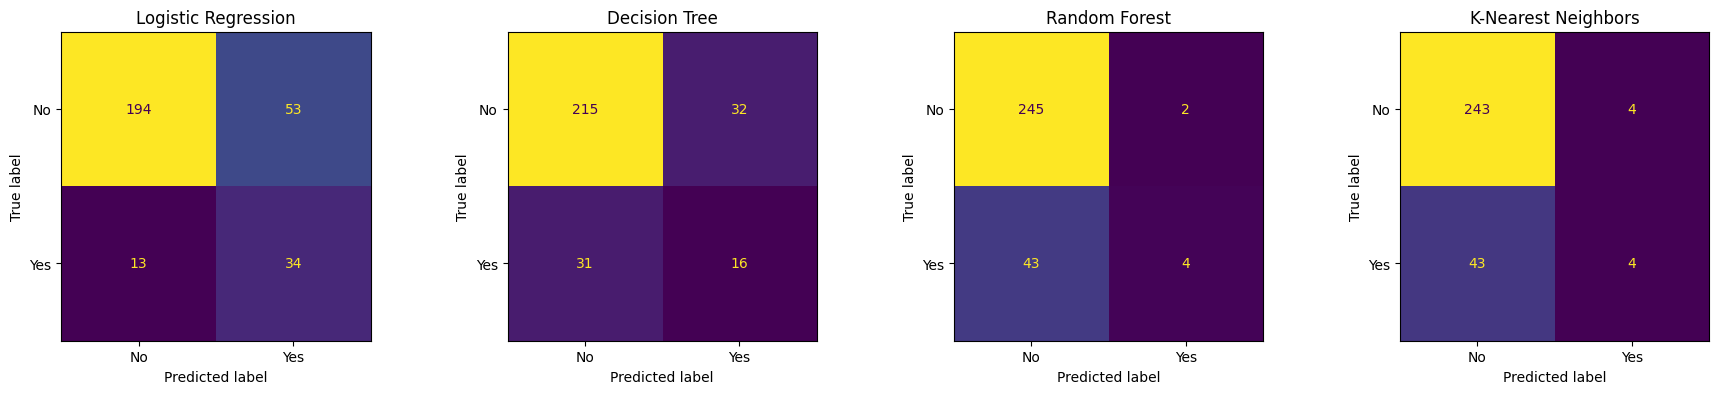

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test_raw))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

ROC curves

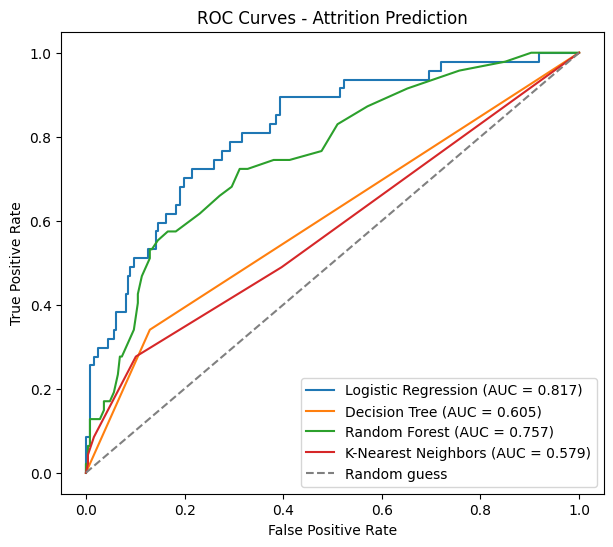

In [15]:
plt.figure(figsize=(7, 6))
for name, pipe in pipelines.items():
    probs = pipe.predict_proba(X_test_raw)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs):.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Attrition Prediction')
plt.legend()
plt.show()

In [16]:
best_name = results_df.sort_values('AUC', ascending=False).iloc[0]['Model']
print("Best model by AUC:", best_name)

artifact = {
    'pipeline': pipelines[best_name],
    'model_name': best_name,
    'input_columns': list(X_raw.columns),     
    'sklearn_version': sklearn.__version__,
}

joblib.dump(cloudpickle.dumps(artifact), "attrition_model.joblib")
print("Saved attrition_model.joblib")

Best model by AUC: Logistic Regression
Saved attrition_model.joblib


## Perfomance Prediction

MODEL BUILDING

In [17]:
X_train_p_raw, X_test_p_raw, y_train_p, y_test_p = train_test_split(
    X_raw, df['PerformanceRating'], test_size=0.2, random_state=42, stratify=df['PerformanceRating'])

bounds_p = {c: (float(X_train_p_raw[c].min()), float(X_train_p_raw[c].max())) for c in BOUND_COLS}

# PercentSalaryHike and PerformanceScore leak the target, so they are left out of the model columns
leaky = ['PercentSalaryHike', 'PerformanceScore']
X_train_p_fe = add_features(X_train_p_raw, bounds_p)
cat_cols_p = [c for c in X_train_p_fe.columns if not pd.api.types.is_numeric_dtype(X_train_p_fe[c])]
num_cols_p = [c for c in X_train_p_fe.columns if c not in cat_cols_p and c not in leaky]

preprocessor_p = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_p),
    ('num', StandardScaler(), num_cols_p)
])   # columns not listed (the leaky ones) are dropped automatically

def make_pipeline_p(classifier):
    return Pipeline([
        ('features', FunctionTransformer(add_features, kw_args={'bounds': bounds_p})),
        ('prep', clone(preprocessor_p)),
        ('clf', classifier),
    ])

pipelines_perf = {}
for name, clf in models.items():
    pipelines_perf[name] = make_pipeline_p(clone(clf)).fit(X_train_p_raw, y_train_p)
print("All performance models trained.")

All performance models trained.


EVALUATION

In [18]:
results_perf = []
for name, pipe in pipelines_perf.items():
    preds = pipe.predict(X_test_p_raw)
    probs = pipe.predict_proba(X_test_p_raw)[:, 1]
    results_perf.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_p, preds),
        'Precision': precision_score(y_test_p, preds, zero_division=0),
        'Recall': recall_score(y_test_p, preds, zero_division=0),
        'F1': f1_score(y_test_p, preds, zero_division=0),
        'AUC': roc_auc_score(y_test_p, probs),
    })
pd.DataFrame(results_perf).round(3)

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.497,0.094,0.267,0.140,0.438
1,Decision Tree,0.731,0.114,0.111,0.112,0.477
2,Random Forest,0.847,0.000,0.000,0.000,0.517
3,K-Nearest Neighbors,0.830,0.000,0.000,0.000,0.528


In [19]:
numeric_df = X_train_p_fe[num_cols_p].copy()          # .copy() avoids modifying a slice
numeric_df['PerformanceRating'] = y_train_p
print(numeric_df.corr()['PerformanceRating'].drop('PerformanceRating').sort_values(key=abs, ascending=False))

IncomePerYearWorked        -0.052762
YearsInCurrentRole          0.037511
Education                  -0.033464
OverallSatisfaction        -0.032492
EnvironmentSatisfaction    -0.028712
StockOptionLevel            0.028543
YearsWithCurrManager        0.027997
RelationshipSatisfaction   -0.025579
DailyRate                   0.024442
DistanceFromHome            0.019239
YearsSinceLastPromotion     0.017506
NumCompaniesWorked         -0.015985
TotalWorkingYears           0.015876
JobSatisfaction            -0.014360
EngagementScore             0.013860
WorkLifeBalance             0.012815
JobInvolvement             -0.012794
JobLevel                   -0.012304
MonthlyIncome              -0.011093
YearsAtCompany              0.010703
HourlyRate                  0.010551
TenureRatio                 0.009154
Age                        -0.007680
TrainingTimesLastYear       0.001721
MonthlyRate                 0.000685
Name: PerformanceRating, dtype: float64


Confusion matrix

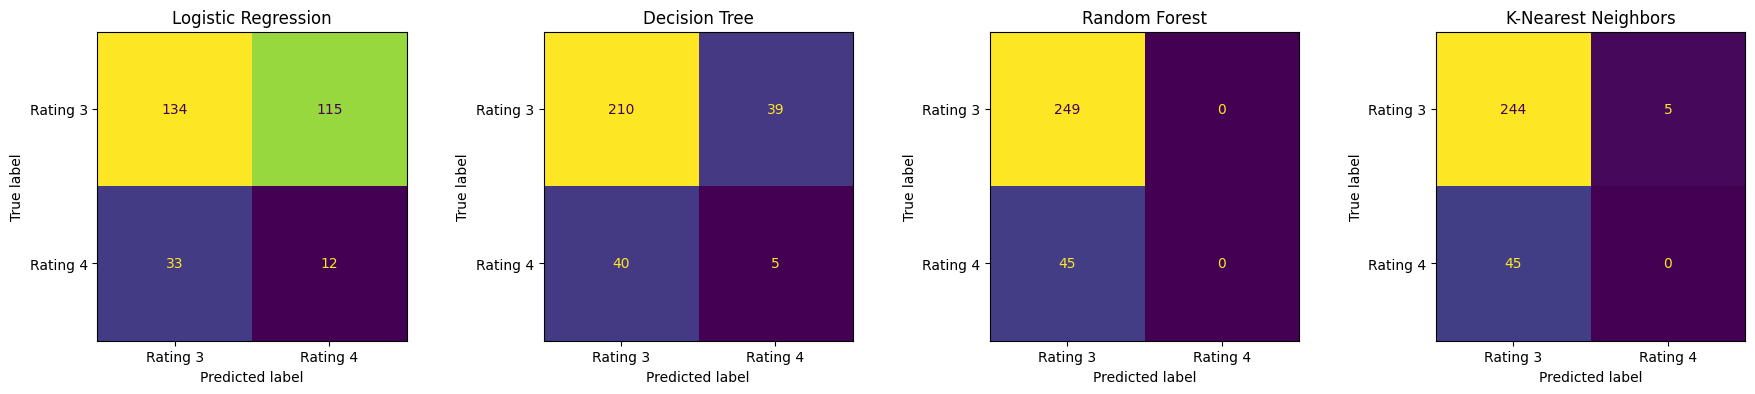

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, pipe) in zip(axes, pipelines_perf.items()):
    cm = confusion_matrix(y_test_p, pipe.predict(X_test_p_raw))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rating 3', 'Rating 4']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

ROC curves

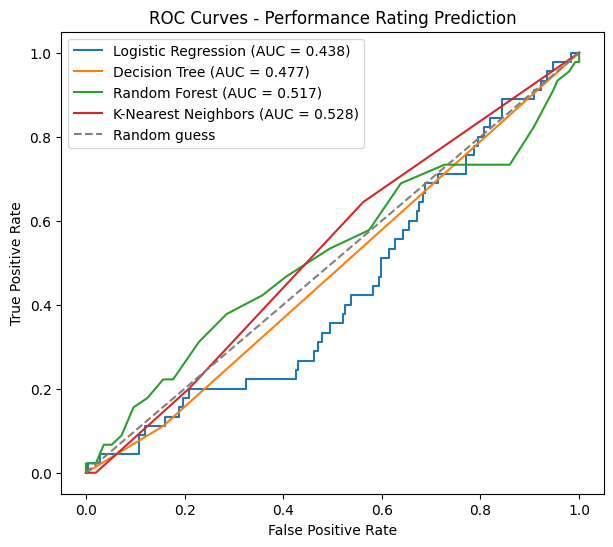

In [21]:
plt.figure(figsize=(7, 6))
for name, pipe in pipelines_perf.items():
    probs = pipe.predict_proba(X_test_p_raw)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_p, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test_p, probs):.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Performance Rating Prediction')
plt.legend()
plt.show()

## Data inefficient for predicting performance